# Матрица ошибок — вариант №14

**Уровень:** основной, пункты 1–6  
**Сценарий:** проверка работ на плагиат  
**Положительный класс («да»):** работа списана  
**Выполнил(а):** впиши своё имя и группу

## Что такое матрица ошибок

Матрица ошибок сравнивает действительное состояние работы с ответом модели.

- Факт — списана ли работа на самом деле.
- Прогноз — считает ли модель работу списанной.
- «Да» означает, что работа списана.
- «Нет» означает, что работа не списана.

Исходные данные: TP = 32, FN = 6, FP = 27, TN = 185.

Общее число работ:

N = 32 + 6 + 27 + 185 = 250.

## 1. Исходная матрица ошибок

Строки — факт, столбцы — прогноз.

| Факт / Прогноз | Да: работа списана | Нет: работа не списана |
|---|---|---|
| Да: работа списана | TP = 32 | FN = 6 |
| Нет: работа не списана | FP = 27 | TN = 185 |

Числовая часть матрицы имеет размер 2×2. Дополнительные строка и столбец нужны для подписей.

## 2. Значение ячеек

- **TP = 32:** модель правильно обнаружила плагиат в 32 списанных работах.
- **FN = 6:** модель пропустила плагиат в 6 списанных работах.
- **FP = 27:** модель ошибочно признала списанными 27 самостоятельных работ.
- **TN = 185:** модель правильно определила, что 185 работ не списаны.

In [5]:
# Исходные данные варианта №14
TP = 32
FN = 6
FP = 27
TN = 185

N = TP + FN + FP + TN

print("Общее число работ:", N)
print()
print("Строки — факт, столбцы — прогноз.")
print("Порядок классов: да, нет.")
print(f"[{TP:3} {FN:3}]")
print(f"[{FP:3} {TN:3}]")

Общее число работ: 250

Строки — факт, столбцы — прогноз.
Порядок классов: да, нет.
[ 32   6]
[ 27 185]


## 3. Расчёт метрик

Все итоговые значения округлены до трёх знаков после запятой.

### Accuracy — доля всех правильных ответов

$$
Accuracy = \frac{TP+TN}{TP+TN+FP+FN}
= \frac{32+185}{250}
= \frac{217}{250}
= 0{,}868.
$$

Модель правильно классифицировала 86,8% работ.

### Precision — точность обнаружения плагиата

$$
Precision = \frac{TP}{TP+FP}
= \frac{32}{32+27}
= \frac{32}{59}
\approx 0{,}542.
$$

Среди работ, которые модель назвала списанными, действительно списаны примерно 54,2%.

### Recall — полнота обнаружения плагиата

$$
Recall = \frac{TP}{TP+FN}
= \frac{32}{32+6}
= \frac{32}{38}
\approx 0{,}842.
$$

Модель обнаружила примерно 84,2% всех списанных работ.

### Specificity — доля правильно распознанных самостоятельных работ

$$
Specificity = \frac{TN}{TN+FP}
= \frac{185}{185+27}
= \frac{185}{212}
\approx 0{,}873.
$$

Модель правильно распознала примерно 87,3% самостоятельных работ.

### F1 — показатель, объединяющий precision и recall

Используем равнозначную формулу через количества объектов:

$$
F_1 = \frac{2TP}{2TP+FP+FN}
= \frac{2\cdot32}{2\cdot32+27+6}
= \frac{64}{97}
\approx 0{,}660.
$$

Эта формула позволяет избежать ошибок из-за промежуточного округления.

In [6]:
accuracy = (TP + TN) / N
precision = TP / (TP + FP)
recall = TP / (TP + FN)
specificity = TN / (TN + FP)
f1 = 2 * TP / (2 * TP + FP + FN)

print(f"Accuracy:    {accuracy:.3f}")
print(f"Precision:   {precision:.3f}")
print(f"Recall:      {recall:.3f}")
print(f"Specificity: {specificity:.3f}")
print(f"F1:          {f1:.3f}")

Accuracy:    0.868
Precision:   0.542
Recall:      0.842
Specificity: 0.873
F1:          0.660


## 4. Модель, которая всегда отвечает «нет»

Такая модель считает любую работу не списанной.

Она правильно классифицирует все самостоятельные работы, которых:

$$
TN + FP = 185 + 27 = 212.
$$

Её accuracy:

$$
Accuracy_{\text{всегда «нет»}}
= \frac{TN+FP}{N}
= \frac{185+27}{250}
= \frac{212}{250}
= 0{,}848.
$$

Сравнение с исходной моделью:

$$
0{,}868 - 0{,}848 = 0{,}020.
$$

Accuracy исходной модели выше на 0,020, или на 2 процентных пункта.

Опираться только на accuracy в этом сценарии нельзя. Самостоятельных работ намного больше, поэтому даже модель, которая вообще не обнаруживает плагиат, получает высокий результат. Дополнительно нужно учитывать precision и recall, чтобы оценивать ложные обвинения и пропущенный плагиат.

## 5. Какая ошибка дороже

В этом сценарии более дорогой ошибкой считаю FP: самостоятельная работа ошибочно признаётся списанной. Такое решение может привести к несправедливому снижению оценки или наказанию студента. Поэтому нужно максимизировать precision, чтобы среди работ, отмеченных как списанные, было как можно меньше ложных обвинений.

## 6. Снижение порога классификации

Порог — это граница, после которой модель отвечает «да». После его снижения модель чаще признаёт работы списанными.

Для варианта №14 задан сдвиг:

**3 FN → TP, 11 TN → FP.**

Три списанные работы, которые модель раньше пропускала, теперь обнаружены. Ещё одиннадцать самостоятельных работ теперь ошибочно признаны списанными.

Новые значения:

- TP = 32 + 3 = 35.
- FN = 6 − 3 = 3.
- FP = 27 + 11 = 38.
- TN = 185 − 11 = 174.

### Новая матрица ошибок

Строки — факт, столбцы — прогноз.

| Факт / Прогноз | Да: работа списана | Нет: работа не списана |
|---|---|---|
| Да: работа списана | TP = 35 | FN = 3 |
| Нет: работа не списана | FP = 38 | TN = 174 |

Проверка общего числа работ:

$$
35 + 3 + 38 + 174 = 250.
$$

### Новый precision

$$
Precision_{\text{новое}}
= \frac{35}{35+38}
= \frac{35}{73}
\approx 0{,}479.
$$

### Новый recall

$$
Recall_{\text{новое}}
= \frac{35}{35+3}
= \frac{35}{38}
\approx 0{,}921.
$$

### Новый F1

$$
F_{1\text{ новое}}
= \frac{2\cdot35}{2\cdot35+38+3}
= \frac{70}{111}
\approx 0{,}631.
$$

### Сравнение результатов

| Метрика | До снижения порога | После снижения порога |
|---|---|---|
| Precision | 0,542 | 0,479 |
| Recall | 0,842 | 0,921 |
| F1 | 0,660 | 0,631 |

### Стала ли модель лучше?

После снижения порога recall вырос с 0,842 до 0,921: модель обнаруживает больше списанных работ. Однако precision снизился с 0,542 до 0,479, а число ложных обвинений выросло с 27 до 38. F1 также снизился с 0,660 до 0,631.

Поскольку в этом сценарии более дорогой ошибкой считаю ложное обвинение в плагиате, после снижения порога модель стала хуже для выбранной цели.

In [7]:
# Сдвиг порога: 3 FN → TP, 11 TN → FP
TP_new = TP + 3
FN_new = FN - 3
FP_new = FP + 11
TN_new = TN - 11

precision_new = TP_new / (TP_new + FP_new)
recall_new = TP_new / (TP_new + FN_new)
f1_new = 2 * TP_new / (2 * TP_new + FP_new + FN_new)

print("Новая матрица: строки — факт, столбцы — прогноз.")
print("Порядок классов: да, нет.")
print(f"[{TP_new:3} {FN_new:3}]")
print(f"[{FP_new:3} {TN_new:3}]")
print()
print("Общее число работ:", TP_new + FN_new + FP_new + TN_new)
print()
print(f"Новый precision: {precision_new:.3f}")
print(f"Новый recall:    {recall_new:.3f}")
print(f"Новый F1:        {f1_new:.3f}")

Новая матрица: строки — факт, столбцы — прогноз.
Порядок классов: да, нет.
[ 35   3]
[ 38 174]

Общее число работ: 250

Новый precision: 0.479
Новый recall:    0.921
Новый F1:        0.631


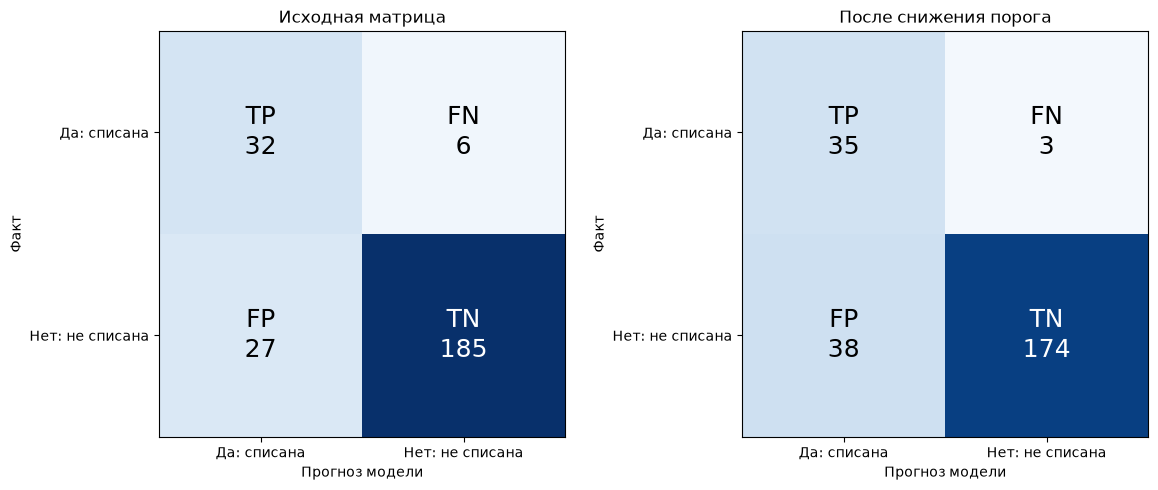

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Строки — факт, столбцы — прогноз.
# Порядок классов: «да», «нет».
matrix_before = np.array([
    [32, 6],
    [27, 185]
])

matrix_after = np.array([
    [35, 3],
    [38, 174]
])

cell_names = [
    ["TP", "FN"],
    ["FP", "TN"]
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

matrices = [matrix_before, matrix_after]
titles = ["Исходная матрица", "После снижения порога"]

for ax, matrix, title in zip(axes, matrices, titles):
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=185)

    ax.set_title(title)
    ax.set_xlabel("Прогноз модели")
    ax.set_ylabel("Факт")

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Да: списана", "Нет: не списана"])
    ax.set_yticklabels(["Да: списана", "Нет: не списана"])

    # Подписи внутри четырёх ячеек
    for row in range(2):
        for col in range(2):
            value = matrix[row, col]
            color = "white" if value > 92.5 else "black"

            ax.text(
                col, row,
                f"{cell_names[row][col]}\n{value}",
                ha="center",
                va="center",
                fontsize=18,
                color=color
            )

plt.tight_layout()
plt.show()